In [1]:
import torch, torchvision, sklearn
print(torch.__version__, torchvision.__version__)

2.14.1+cpu 0.29.1+cpu


In [3]:
from pathlib import Path
import json, random
import numpy as np
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cpu"
DATA_DIR = Path("data/wikiart_subset")
IMAGE_SIZE = 64
BATCH_SIZE = 128

# 1. Load every image once into one tensor
ds = datasets.ImageFolder(DATA_DIR, transform=transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)), transforms.ToTensor()]))
CLASSES = ds.classes
X_all = torch.stack([img for img, _ in ds])   # (N, 3, 64, 64), pixels in [0, 1]
y_all = torch.tensor(ds.targets)               # (N,), int64
y_np = y_all.numpy()

# 2. Stratified split 70 / 15 / 15
idx = np.arange(len(y_np))
train_idx, tmp_idx = train_test_split(idx, test_size=0.30, stratify=y_np, random_state=SEED)
val_idx, test_idx = train_test_split(tmp_idx, test_size=0.50, stratify=y_np[tmp_idx], random_state=SEED)
train_idx, val_idx, test_idx = map(torch.from_numpy, (train_idx, val_idx, test_idx))

# 3. Standardise with the TRAINING mean and std only
mean = X_all[train_idx].mean().item()
std = X_all[train_idx].std().item()
X = (X_all - mean) / std

# 4. DataLoaders
train_loader = DataLoader(TensorDataset(X[train_idx], y_all[train_idx]), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(TensorDataset(X[val_idx],   y_all[val_idx]),   batch_size=1000)
test_loader  = DataLoader(TensorDataset(X[test_idx],  y_all[test_idx]),  batch_size=1000)

# Save the split so the group tests on the same images
Path("outputs").mkdir(exist_ok=True)
Path("outputs/split.json").write_text(json.dumps(
    {"train": train_idx.tolist(), "val": val_idx.tolist(), "test": test_idx.tolist()}))

print("classes:", CLASSES)
print(f"mean {mean:.4f}, std {std:.4f}")
for name, ids in [("train", train_idx), ("val", val_idx), ("test", test_idx)]:
    print(f"{name:5s} {len(ids):4d} | per class {np.bincount(y_np[ids.numpy()])}")

classes: ['Baroque', 'Cubism', 'Impressionism', 'Pop_Art', 'Ukiyo_e']
mean 0.4921, std 0.2608
train  350 | per class [70 70 70 70 70]
val     75 | per class [15 15 15 15 15]
test    75 | per class [15 15 15 15 15]


In [4]:
from torchvision.models import resnet18, ResNet18_Weights
import time

# Pretrained ResNet-18, last layer removed: it now outputs 512 features per image
backbone = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)   # downloads ~45 MB the first time
backbone.fc = nn.Identity()
backbone.eval()
for p in backbone.parameters():
    p.requires_grad = False   # frozen: no weight of the backbone is trained

# ResNet expects 224x224 images normalised with the ImageNet mean/std (not our own standardisation)
resnet_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
ds_r = datasets.ImageFolder(DATA_DIR, transform=resnet_tf)
assert ds_r.targets == ds.targets, "same image order as cell 1, so split.json still applies"

# Extract the features once
feats = []
t0 = time.perf_counter()
with torch.no_grad():
    for xb, _ in DataLoader(ds_r, batch_size=32):
        feats.append(backbone(xb))
elapsed = time.perf_counter() - t0
F_all = torch.cat(feats)   # (500, 512)

print("features:", tuple(F_all.shape))
print(f"CPU time: {1000 * elapsed / len(F_all):.1f} ms per image (batches of 32)")

5.9%

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\migue/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


features: (500, 512)
CPU time: 10.7 ms per image (batches of 32)


In [6]:
# Course helpers (TP04/TP05): training loop and evaluation

def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            logits = model(xb)
            total_loss += loss_fn(logits, yb).item() * len(yb)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += len(yb)
    return total_loss / total, correct / total


def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    running, total = 0.0, 0
    for xb, yb in loader:
        loss = loss_fn(model(xb), yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running += loss.item() * len(yb)
        total += len(yb)
    return running / total


def fit(model, train_loader, val_loader, loss_fn, optimizer, n_epochs, verbose=True):
    history = {"train_loss": [], "val_loss": [], "val_acc": []}
    for epoch in range(n_epochs):
        train_loss = train_one_epoch(model, train_loader, loss_fn, optimizer)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        if verbose:
            print(f"epoch {epoch + 1:2d} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | val acc {val_acc:.3f}")
    return history

epoch  1 | train loss 1.6053 | val loss 1.3763 | val acc 0.413
epoch  2 | train loss 1.2250 | val loss 1.1527 | val acc 0.627
epoch  3 | train loss 1.0014 | val loss 0.9633 | val acc 0.720
epoch  4 | train loss 0.8410 | val loss 0.8722 | val acc 0.773
epoch  5 | train loss 0.7318 | val loss 0.7978 | val acc 0.800
epoch  6 | train loss 0.6677 | val loss 0.7629 | val acc 0.787
epoch  7 | train loss 0.5837 | val loss 0.7188 | val acc 0.800
epoch  8 | train loss 0.5310 | val loss 0.6902 | val acc 0.813
epoch  9 | train loss 0.4847 | val loss 0.6814 | val acc 0.813
epoch 10 | train loss 0.4529 | val loss 0.6551 | val acc 0.827
epoch 11 | train loss 0.4240 | val loss 0.6457 | val acc 0.853
epoch 12 | train loss 0.3961 | val loss 0.6270 | val acc 0.840
epoch 13 | train loss 0.3719 | val loss 0.6286 | val acc 0.827
epoch 14 | train loss 0.3497 | val loss 0.6104 | val acc 0.853
epoch 15 | train loss 0.3362 | val loss 0.6032 | val acc 0.827
epoch 16 | train loss 0.3167 | val loss 0.5988 | val ac

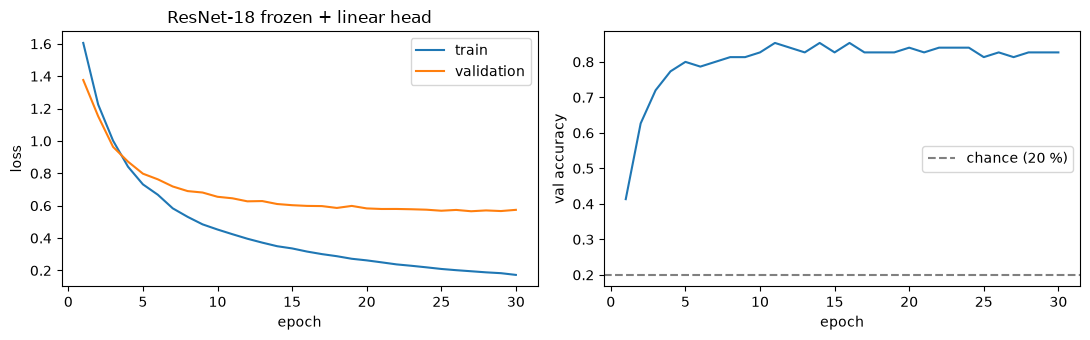

In [7]:
torch.manual_seed(SEED)
F_train, F_val, F_test = F_all[train_idx], F_all[val_idx], F_all[test_idx]
y_train, y_val, y_test = y_all[train_idx], y_all[val_idx], y_all[test_idx]

ftrain_loader = DataLoader(TensorDataset(F_train, y_train), batch_size=32, shuffle=True)
fval_loader   = DataLoader(TensorDataset(F_val, y_val), batch_size=1000)
ftest_loader  = DataLoader(TensorDataset(F_test, y_test), batch_size=1000)   # used once, at the very end

head = nn.Linear(512, len(CLASSES))   # 512 * 5 + 5 = 2565 trainable parameters
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(head.parameters(), lr=1e-3)
history_head = fit(head, ftrain_loader, fval_loader, loss_fn, optimizer, n_epochs=30)

# Training curves
epochs = range(1, len(history_head["train_loss"]) + 1)
plt.figure(figsize=(11, 3.5))
plt.subplot(1, 2, 1)
plt.plot(epochs, history_head["train_loss"], label="train")
plt.plot(epochs, history_head["val_loss"], label="validation")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.title("ResNet-18 frozen + linear head")
plt.subplot(1, 2, 2)
plt.plot(epochs, history_head["val_acc"])
plt.axhline(1 / len(CLASSES), ls="--", c="grey", label="chance (20 %)")
plt.xlabel("epoch"); plt.ylabel("val accuracy"); plt.legend()
plt.tight_layout(); plt.show()